In [1]:
import pandas as pd
import geopandas as gpd
import h3pandas
from shapely.geometry import Polygon
import tskit
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
import PIL
from IPython.display import display, Image
import io

import rasterio
from rasterio.vrt import WarpedVRT
from rasterio import transform
import rasterstats
import matplotlib.pyplot as plt
import rasterio.mask
from rasterio.plot import show

import random
import math
import glob

import sys
sys.path.append("../..")
import sim_utils
import importlib
importlib.reload(sim_utils)

<module 'sim_utils' from '/Users/jameskitchens/Documents/GitHub/terracotta_manuscript_code/simulations/arabidopsis/2_creating_input_files/../../sim_utils.py'>

### Create a bounding box around the region of interest

In [2]:
# Make a list of latitudes and longitudes of the four points
# the fifth point is the first point to make last edge of polygon go back to start

lat_point_list = [33.619523, 33.968163, 72.575236, 72.533312, 33.619523]
lon_point_list = [-12.321952, 46.271179, 40.677562, -11.343070, -12.321952]

polygon_geometry = Polygon(zip(lon_point_list, lat_point_list))
rectangle_polygon_geometry = Polygon([[polygon_geometry.bounds[0], polygon_geometry.bounds[1]],
                                      [polygon_geometry.bounds[2], polygon_geometry.bounds[1]],
                                      [polygon_geometry.bounds[2], polygon_geometry.bounds[3]],
                                      [polygon_geometry.bounds[0], polygon_geometry.bounds[3]],
                                      [polygon_geometry.bounds[0], polygon_geometry.bounds[1]]])
crs = "epsg:4326"
shp = gpd.GeoDataFrame(index=[0], crs=crs, geometry=[rectangle_polygon_geometry])

### Converting to hexagons

In [3]:
resolution = 2
hex_euro = shp.h3.polyfill_resample(resolution).sort_index().reset_index()
hex_euro["deme"] = hex_euro.index

### Add an artificial directional pull

In [4]:
xs = hex_euro.centroid.x
ys = hex_euro.centroid.y

hex_euro["from_top"] = 0.00000000001 * (10000000 ** (1-((ys - min(ys)) / (max(ys) - min(ys)))))

mean_x = np.mean(xs)
mean_y = np.mean(ys)
distances = (xs-mean_x)**2 + (ys-mean_y)**2
hex_euro["from_center"] = 0.00000000001 * (1000000 ** (1 - (distances - min(distances)) / (max(distances) - min(distances))))

/var/folders/q7/rz2nckpx02s10jlx05wbk6c00000gn/T/ipykernel_11408/1027857580.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  xs = hex_euro.centroid.x
/var/folders/q7/rz2nckpx02s10jlx05wbk6c00000gn/T/ipykernel_11408/1027857580.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  ys = hex_euro.centroid.y


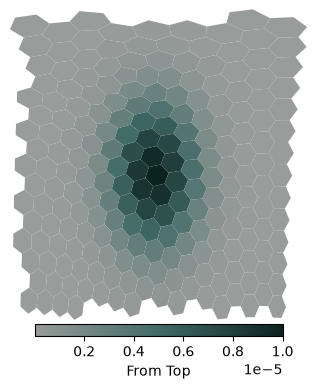

In [5]:
colors = ["#989C9A", "#416A66", "#0C2320"]
cmap = LinearSegmentedColormap.from_list("mycmap", colors)

base = hex_euro.plot(
    column="from_center",
    legend=True,
    legend_kwds={"label": "From Top", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap=cmap
)

plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

### Mask out islands of suitability

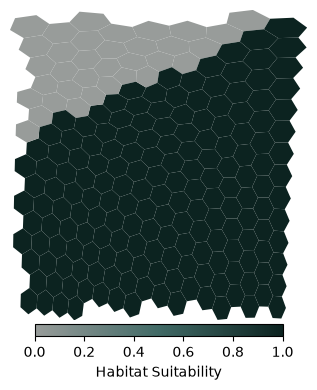

In [7]:
mask = []
for i in range(len(xs)):
    if (ys[i] > xs[i]*0.25 + 60):
        mask.append(0)
    else:
        mask.append(1)
hex_euro["mask"] = mask

base = hex_euro.plot(
    column=f"mask",
    legend=True,
    legend_kwds={"label": "Habitat Suitability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap=cmap,
    vmin=0,
    vmax=1
)

plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

### Calculate mean suitability within each deme over time

In [8]:
for t in range(0, 121000, 1000):
    if (t < 21000 or t % 2000 == 0):
        with rasterio.open(f"../1_generating_suitability_maps/datasets/Beyer_High-resolutionTerrestrialClimate_2020/data/suitability_reconstructions/{t}.grd") as src_dst:
            mean_suitability = []
            for stat in rasterstats.zonal_stats(
                hex_euro,
                #src_dst.read(1),
                np.nan_to_num(src_dst.read(1), nan=0.0),
                affine=src_dst.transform,
                stats="mean",
                nodata=-999999
            ):
                mean_suitability.append(stat["mean"])
            if t > 10000:
                hex_euro.loc[:,f"mean_suitability_{t}"] = mean_suitability * hex_euro["mask"] + hex_euro["from_center"]
            else:
                hex_euro.loc[:,f"mean_suitability_{t}"] = mean_suitability + hex_euro["from_center"]

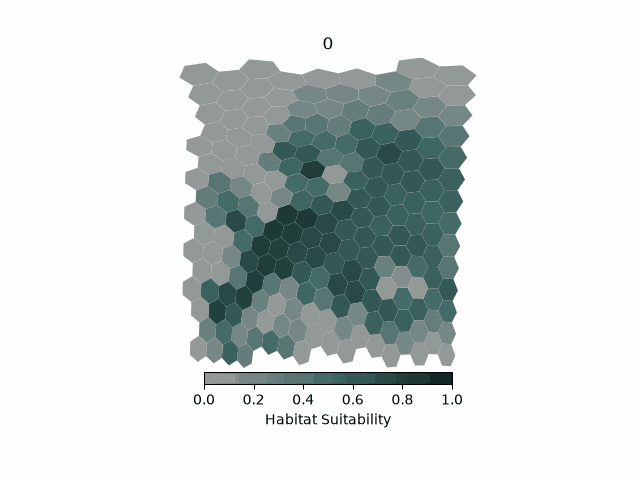

In [107]:
colors = ["#989C9A", "#416A66", "#0C2320"]
cmap = LinearSegmentedColormap.from_list("mycmap", colors)

images = []

for t in range(0, 121000, 1000):
    if (t < 21000 or t % 2000 == 0):
        base = hex_euro.plot(
            column=f"mean_suitability_{t}",
            legend=True,
            legend_kwds={"label": "Habitat Suitability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
            cmap=cmap,
            vmin=0,
            vmax=1
        )

        plt.title(t)
        plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
        plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
        plt.axis("off")
        plt.savefig(f"figures/suitability_maps/{t}.png")
        plt.close()
        images.append(PIL.Image.open(f"figures/suitability_maps/{t}.png"))

images[0].save("suitability_maps.gif", save_all=True, append_images=images[1:], duration=250, loop=0)
display(Image("suitability_maps.gif"))

### Place samples

In [108]:
total_present_suit = sum(hex_euro["mean_suitability_0"])
weights = hex_euro["mean_suitability_0"] / total_present_suit
random_demes = random.choices(hex_euro["deme"], weights=weights, k=50)

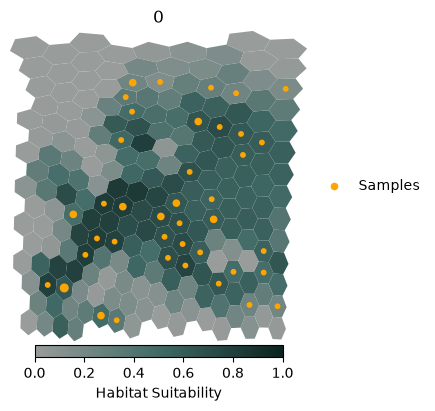

In [109]:
base = hex_euro.plot(
    column=f"mean_suitability_0",
    legend=True,
    legend_kwds={"label": "Habitat Suitability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
    cmap=cmap,
    vmin=0,
    vmax=1
)

xs = []
ys = []
ss = []
for i,row in hex_euro.iterrows():
    count = random_demes.count(row["deme"])
    if count > 0:
        center = row["geometry"].centroid
        xs.append(center.x)
        ys.append(center.y)
        ss.append(count*10)

plt.scatter(xs, ys, s=ss, color="orange", zorder=20, label="Samples")

plt.legend(bbox_to_anchor=(1.0, 0.5), loc="center left", frameon=False)
plt.title(0)
plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
plt.axis("off")
plt.show()

### Output to files

In [110]:
samples = pd.DataFrame({"id":range(len(random_demes)), "deme":random_demes})
samples.to_csv("dataset/samples.tsv", sep="\t", index=False)

In [111]:
buffered_hexs = hex_euro.loc[:, :]
buffered_hexs["geometry"] = buffered_hexs.buffer(0.001)
with open("dataset/demes.tsv", "w") as outfile:
    outfile.write("id\txcoord\tycoord\tsuitability\n")
    with open("dataset/connections.tsv", "w") as connectionsfile:
        connectionsfile.write("id\tdeme_0\tdeme_1\tmigration_modifier\n")
        connection_id = 0
        for i, row in buffered_hexs.iterrows():
            neighbors = np.array(buffered_hexs[buffered_hexs.geometry.touches(row['geometry'])].deme)
            #overlapping neighbors use if discrepances found with touches
            overlap = np.array(buffered_hexs[buffered_hexs.geometry.overlaps(row['geometry'])].deme)
            neighbors = [str(d) for d in np.sort(np.union1d(neighbors, overlap))]

            for neighbor in neighbors:
                if int(neighbor) > row["deme"]:
                    connectionsfile.write(f"{connection_id}\t{row["deme"]}\t{neighbor}\t{1}\n")
                    connection_id += 1
                
            center = row["geometry"].centroid
            s = row[f"mean_suitability_0"]
            suitability = f"0:{s}"
            for t in range(1000, 121000, 1000):
                if (t < 21000 or t % 2000 == 0):
                    s = row[f"mean_suitability_{t}"] 
                    suitability += f",{t}:{s}"
            outfile.write(f"{row["deme"]}\t{center.x}\t{center.y}\t{suitability}\n")

/var/folders/q7/rz2nckpx02s10jlx05wbk6c00000gn/T/ipykernel_15596/3216090447.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  buffered_hexs["geometry"] = buffered_hexs.buffer(0.001)


#### Add fake sample/population

In [112]:
with open("dataset/demes_with_extra_sample.tsv", "w") as outfile:
    with open("dataset/demes.tsv", "r") as demesfile:
        for line in demesfile:
            outfile.write(line)
        outfile.write(f"9999\t60\t60\t1\n")

with open("dataset/samples_with_extra_sample.tsv", "w") as outfile:
    with open("dataset/samples.tsv", "r") as samplesfile:
        for line in samplesfile:
            outfile.write(line)
        sample = line.split("\t")[0]
        outfile.write(f"{int(sample)+1}\t9999\n")

In [113]:
sim_utils.create_trees_files(
    demes_path="dataset/demes_with_extra_sample.tsv",
    connections_path="dataset/connections.tsv",
    samples_path="dataset/samples_with_extra_sample.tsv",
    number_of_trees=1000,
    pop_size=2500,
    migration_rate=0.001,
    end_time=121000,
    output_directory="dataset"
)

The provenance information for the resulting tree sequence is 13.56MB. This is nothing to worry about as provenance is a good thing to have, but if you want to save this memory/storage space you can disable provenance recording by setting record_provenance=False


In [114]:
samples = pd.read_csv("dataset/samples_with_extra_sample.tsv", sep="\t")
for path in glob.glob("dataset/trees/*"):
    p = path.split("/")[-1]
    ts = tskit.load(path)
    ts = ts.simplify(samples=samples["id"][:-1], keep_unary=True)
    ts.dump(f"dataset/trees/{p}")

### View ancestral locations

In [115]:
import sys
sys.path.append("/Users/jameskitchens/Documents/GitHub/terracotta")
import terracotta as tct
import importlib
importlib.reload(tct)

demes = pd.read_csv("dataset/demes_with_extra_sample.tsv", sep="\t")
connections = pd.read_csv("dataset/connections.tsv", sep="\t")
samples = pd.read_csv("dataset/samples_with_extra_sample.tsv", sep="\t")
world_map = tct.WorldMap(demes, connections, samples)

In [116]:
suit_times = np.array([t for t in range(0, 122000, 1000) if (t < 21000 or t % 2000 == 0)])

lineage = []
locus = []
time = []
deme = []

for path in glob.glob("dataset/trees/*"):
    ts = tskit.load(path)
    tree = ts.first()
    for sample in ts.samples():
        a = sample
        previous_t = 0
        while a != -1:
            t = ts.node(a).time
            pop = int(ts.population(ts.node(a).population).metadata["name"].split("_")[-1])
            for st in suit_times[np.where((suit_times > previous_t) & (suit_times < t))[0]]:
                lineage.append(sample)
                locus.append(path)
                time.append(st)
                deme.append(pop)
            lineage.append(sample)
            locus.append(path)
            time.append(t)
            deme.append(pop)
            a = tree.parent(a)
            previous_t = t

locations = pd.DataFrame({"locus": locus, "lineage":lineage, "time":time, "deme":deme})

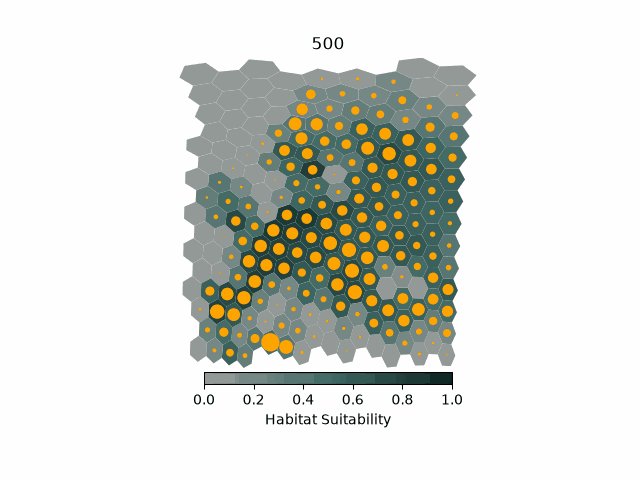

In [117]:
images = []

for t in range(0, 122000, 1000):
    if (t < 21000 or t % 2000 == 0):
        base = hex_euro.plot(
            column=f"mean_suitability_{t}",
            legend=True,
            legend_kwds={"label": "Habitat Suitability", "orientation": "horizontal", "shrink": 0.5, "pad": 0.01},
            cmap=cmap,
            vmin=0,
            vmax=1
        )

        filtered = locations.loc[(locations["time"]<=t+500)]
        filled_demes = list(filtered.loc[filtered.groupby(["locus", "lineage"])["time"].idxmax()]["deme"])

        xs = []
        ys = []
        ss = []
        for i,row in hex_euro.iterrows():
            count = filled_demes.count(row["deme"])
            if count > 0:
                center = row["geometry"].centroid
                xs.append(center.x)
                ys.append(center.y)
                ss.append(count*0.1)
        
        plt.scatter(xs, ys, s=ss, color="orange", zorder=20, label="Lineages")

        plt.title(t+500)
        plt.xlim(hex_euro.total_bounds[0], hex_euro.total_bounds[2])
        plt.ylim(hex_euro.total_bounds[1], hex_euro.total_bounds[3])
        plt.axis("off")
        plt.savefig(f"figures/ancestral_locations/{t+500}.png")
        plt.close()
        images.append(PIL.Image.open(f"figures/ancestral_locations/{t+500}.png"))

images[0].save("ancestral_locations.gif", save_all=True, append_images=images[1:], duration=250, loop=0)
display(Image("ancestral_locations.gif"))